In [1]:
from google.colab import files
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:

import csv
data = pd.read_csv('/content/Day-14_dengue.csv', quoting=csv.QUOTE_NONE)

In [3]:
data.head()

,Name,Fever,Headache,JointPain,Bleeding,Dengue
0,Jeremy Long,0.0,0.0,1.0,1.0,1.0
1,Cassandra Glover,1.0,1.0,1.0,0.0,1.0
2,Aaron Adams MD,0.0,1.0,1.0,0.0,0.0
3,Elizabeth Thomas,0.0,1.0,0.0,1.0,1.0
4,Mathew Perez,0.0,0.0,1.0,0.0,1.0


In [4]:
data.tail()

,Name,Fever,Headache,JointPain,Bleeding,Dengue
871234,Sophia Johnson,1.0,0.0,1.0,1.0,1.0
871235,Jeffery Davis,0.0,1.0,1.0,1.0,0.0
871236,Christopher Schwartz,0.0,1.0,0.0,0.0,1.0
871237,Richard Hutchinson,0.0,0.0,1.0,1.0,0.0
871238,Christine,NaN,NaN,NaN,NaN,NaN


In [5]:
data.shape

(871239, 6)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 871239 entries, 0 to 871238
Data columns (total 6 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Name       871239 non-null  object 
 1   Fever      871238 non-null  float64
 2   Headache   871238 non-null  float64
 3   JointPain  871238 non-null  float64
 4   Bleeding   871238 non-null  float64
 5   Dengue     871238 non-null  float64
dtypes: float64(5), object(1)
memory usage: 39.9+ MB


In [7]:
data.isnull().sum()

,0
Name,0
Fever,1
Headache,1
JointPain,1
Bleeding,1
Dengue,1


In [8]:
data.min(numeric_only=True)

,0
Fever,0.0
Headache,0.0
JointPain,0.0
Bleeding,0.0
Dengue,0.0


In [9]:
data.max(numeric_only=True)

,0
Fever,1.0
Headache,1.0
JointPain,1.0
Bleeding,1.0
Dengue,1.0


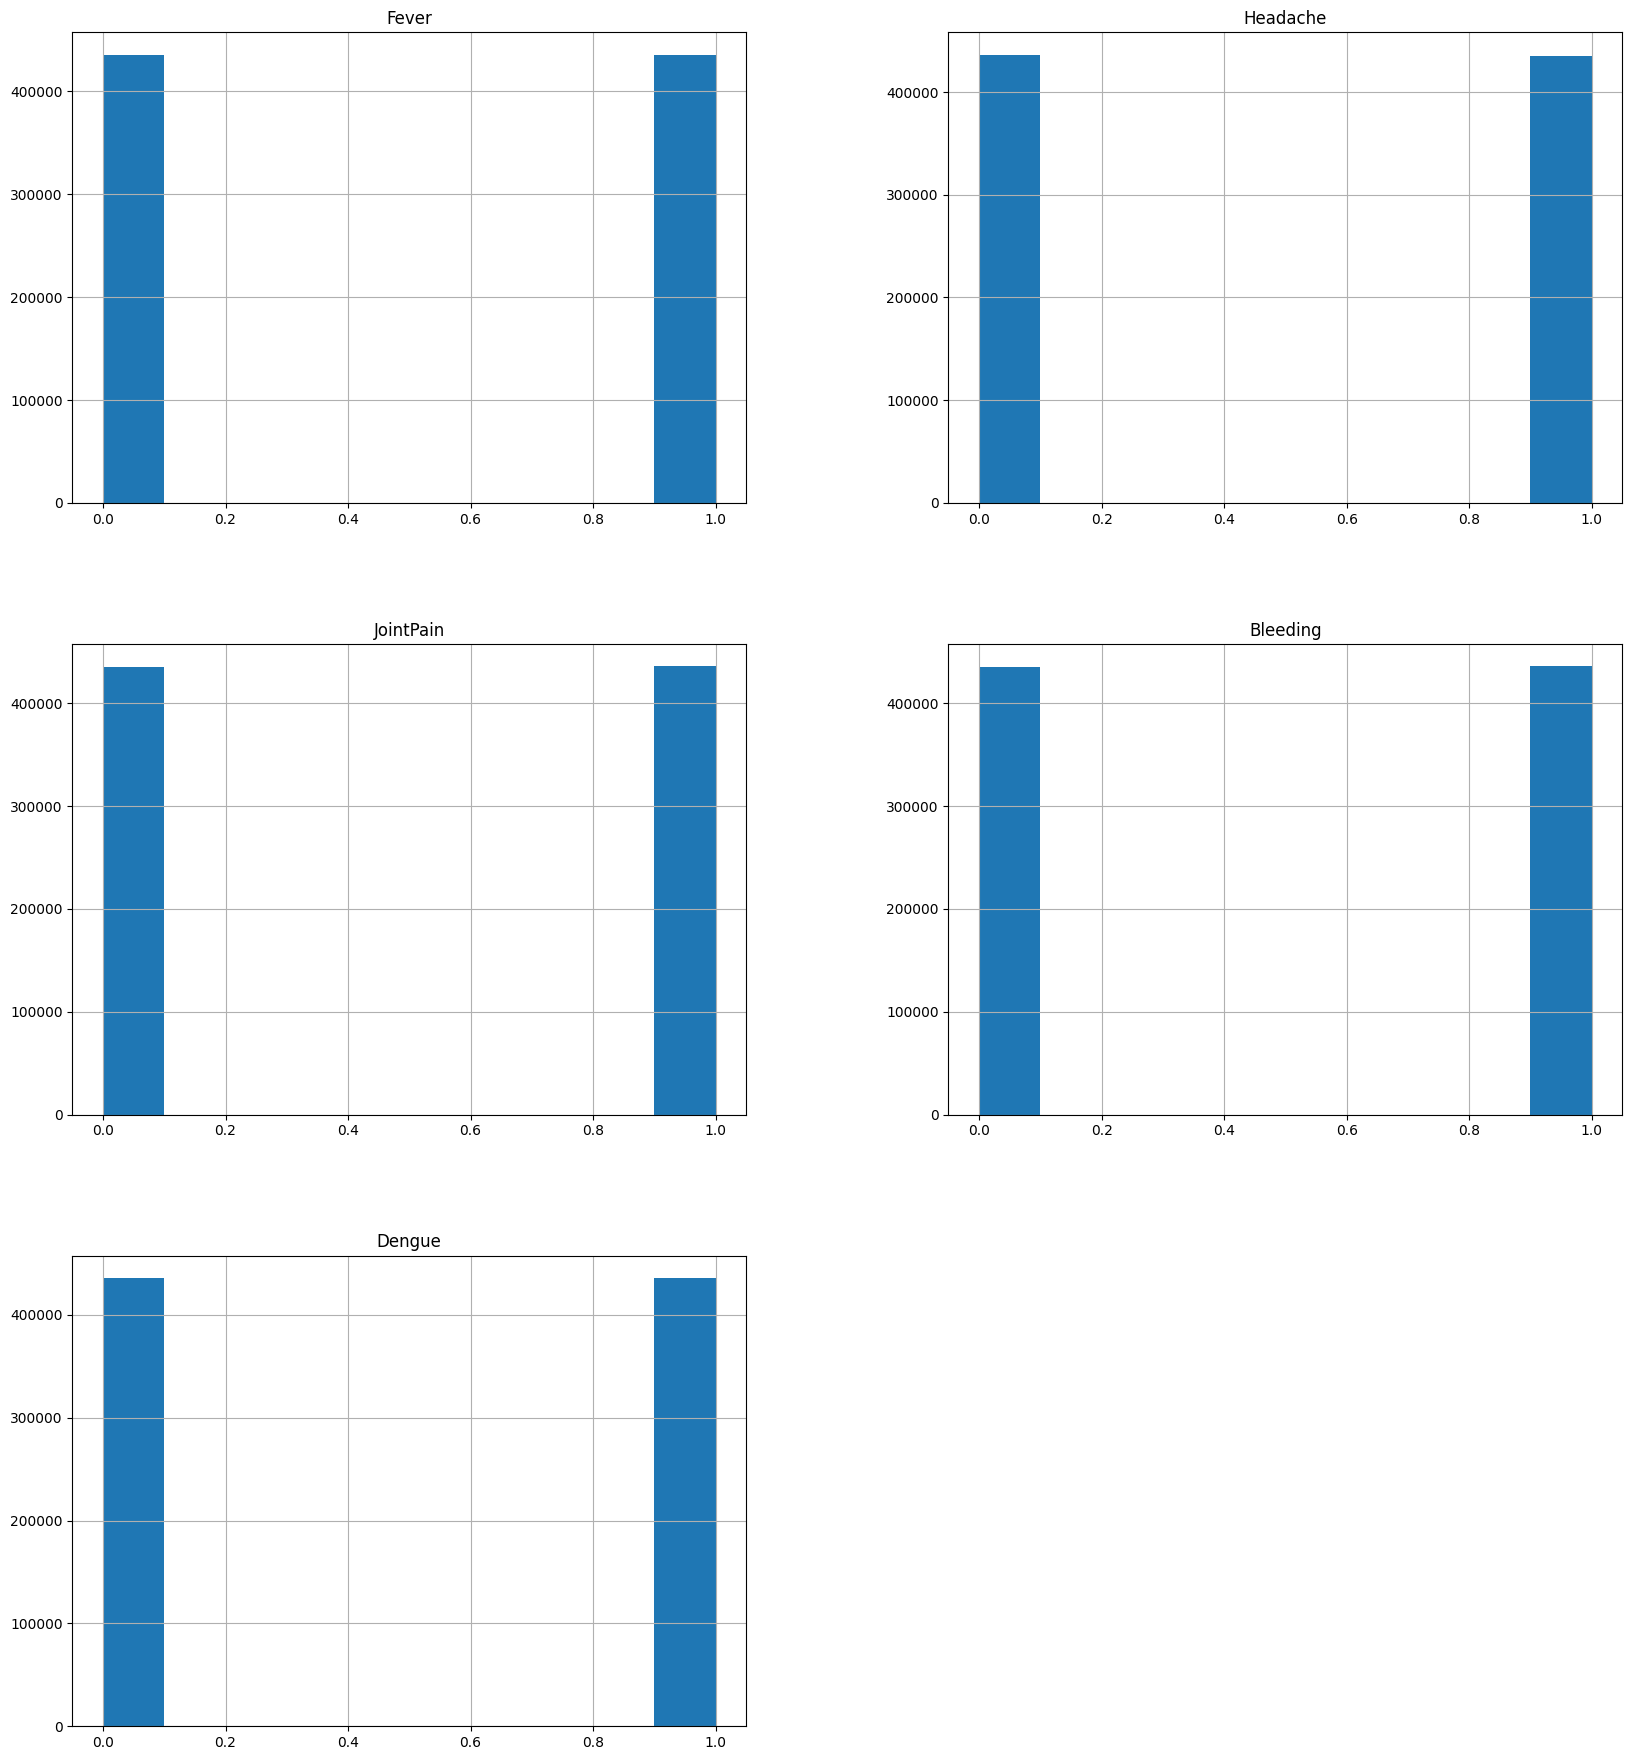

In [10]:
data.hist(figsize=(20, 22))
plt.show()

In [11]:
data.columns

Index(['Name', 'Fever', 'Headache', 'JointPain', 'Bleeding', 'Dengue'], dtype='object')

Correlation Matrix:


,Fever,Headache,JointPain,Bleeding,Dengue
Fever,1.000000,0.001122,0.001182,0.000703,0.001800
Headache,0.001122,1.000000,0.001321,-0.001909,-0.000079
JointPain,0.001182,0.001321,1.000000,-0.000459,0.000124
Bleeding,0.000703,-0.001909,-0.000459,1.000000,0.000787
Dengue,0.001800,-0.000079,0.000124,0.000787,1.000000


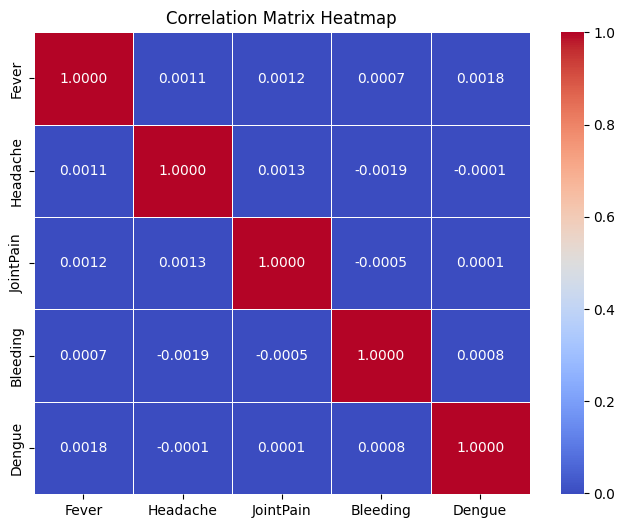

In [12]:
numeric_data = data.select_dtypes(include=[np.number])

correlation_matrix = numeric_data.corr()
print("Correlation Matrix:")
display(correlation_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.4f', linewidths=0.5)
plt.title('Correlation Matrix Heatmap')
plt.show()

In [13]:
col1 = 'Fever'
col2 = 'Dengue'

specific_correlation = data[col1].corr(data[col2])
print(f"Correlation between '{col1}' and '{col2}': {specific_correlation:.6f}")

Correlation between 'Fever' and 'Dengue': 0.001800


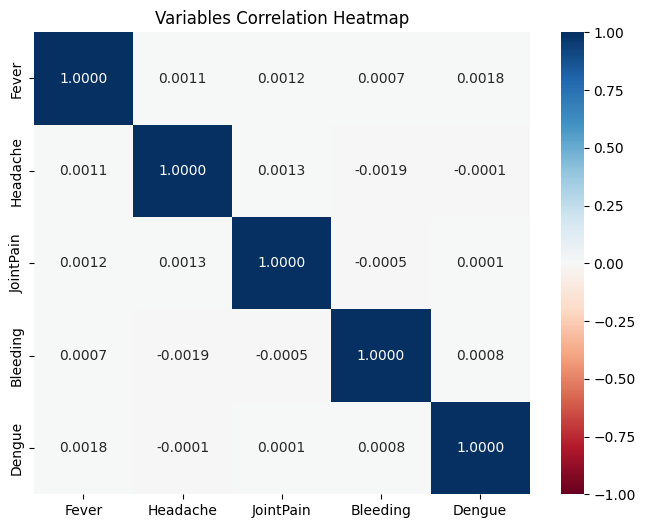

In [14]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='RdBu', vmin=-1, vmax=1, fmt='.4f')
plt.title('Variables Correlation Heatmap')
plt.show()

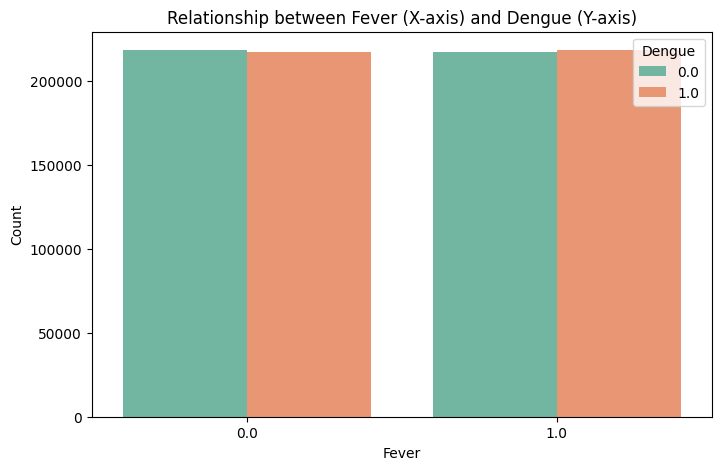

In [15]:
x_var = 'Fever'
y_var = 'Dengue'

plt.figure(figsize=(8, 5))
sns.countplot(data=data, x=x_var, hue=y_var, palette='Set2')
plt.title(f'Relationship between {x_var} (X-axis) and {y_var} (Y-axis)')
plt.xlabel(x_var)
plt.ylabel('Count')
plt.legend(title=y_var)
plt.show()

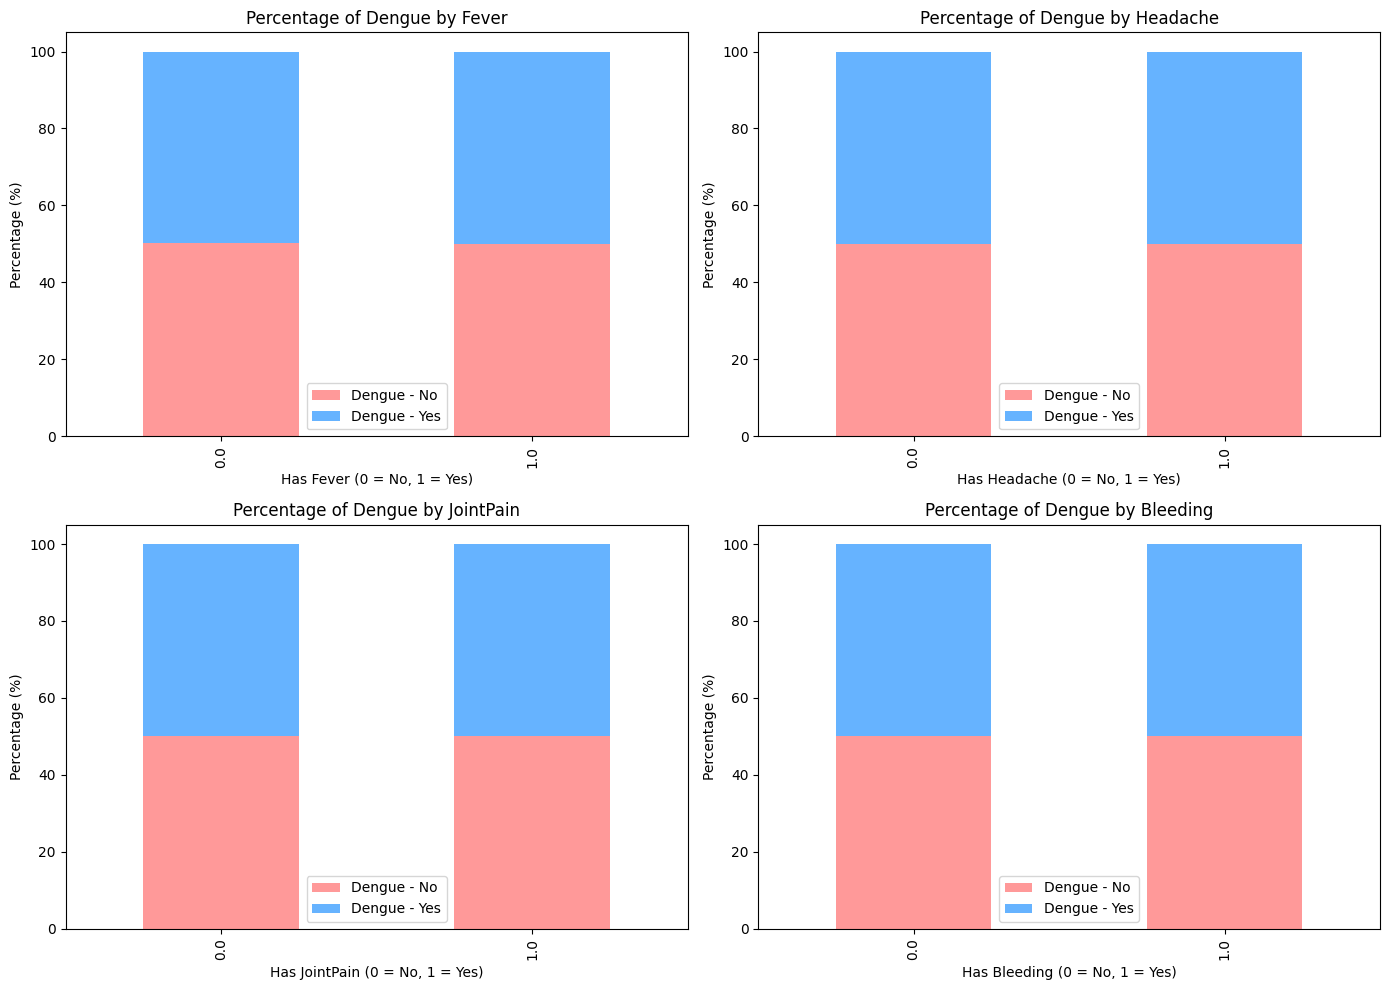

In [16]:
symptoms = ['Fever', 'Headache', 'JointPain', 'Bleeding']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, symptom in enumerate(symptoms):
    ct = pd.crosstab(data[symptom], data['Dengue'], normalize='index') * 100
    ct.plot(kind='bar', stacked=True, color=['#ff9999','#66b3ff'], ax=axes[i])
    axes[i].set_title(f'Percentage of Dengue by {symptom}')
    axes[i].set_ylabel('Percentage (%)')
    axes[i].set_xlabel(f'Has {symptom} (0 = No, 1 = Yes)')
    axes[i].legend(['Dengue - No', 'Dengue - Yes'])

plt.tight_layout()
plt.show()

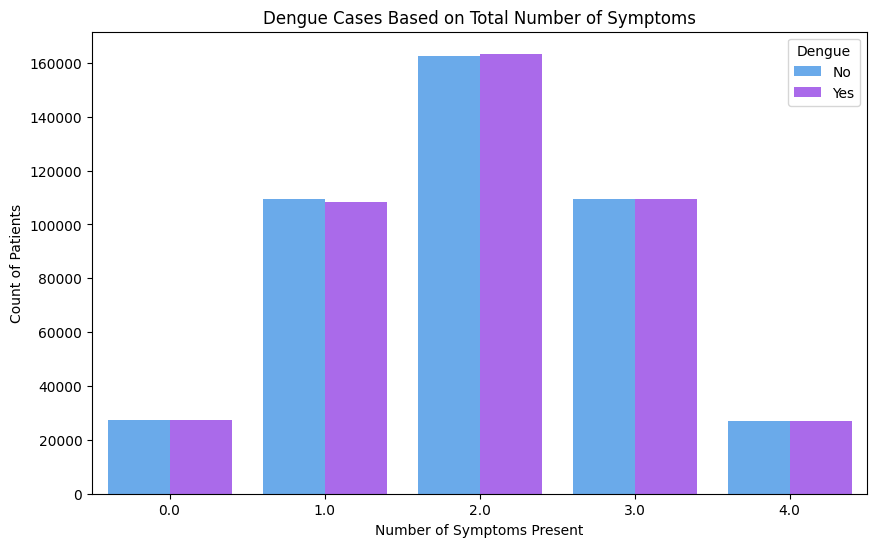

In [17]:
data['Total_Symptoms'] = data[symptoms].sum(axis=1)

plt.figure(figsize=(10, 6))
sns.countplot(data=data, x='Total_Symptoms', hue='Dengue', palette='cool')
plt.title('Dengue Cases Based on Total Number of Symptoms')
plt.xlabel('Number of Symptoms Present')
plt.ylabel('Count of Patients')
plt.legend(title='Dengue', labels=['No', 'Yes'])
plt.show()

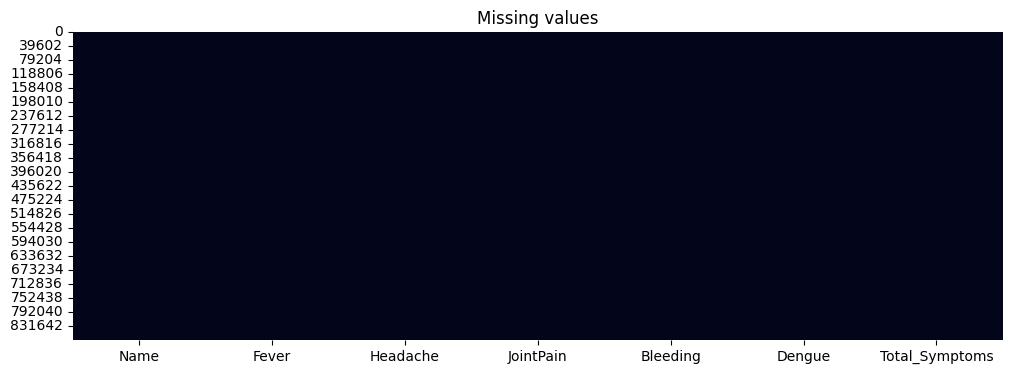

In [18]:
plt.figure(figsize=(12,4))
sns.heatmap(data.isna(), cbar=False)
plt.title("Missing values")
plt.show()

### ১. ডেটা ক্লিনিং (মিসিং ভ্যালু বাদ দেওয়া)

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

X = clean_data[symptoms]
y = clean_data['Dengue']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Model Accuracy: 0.5011076167301777

Classification Report:
              precision    recall  f1-score   support

         0.0       0.50      0.63      0.56     87019
         1.0       0.50      0.38      0.43     87229

    accuracy                           0.50    174248
   macro avg       0.50      0.50      0.49    174248
weighted avg       0.50      0.50      0.49    174248



### 5. Visualizing Feature Importance (Odds Ratios)
Let's extract the coefficients from our model to see which symptoms increase or decrease the likelihood of having Dengue.

In [22]:
importance = model.coef_[0]
feature_importance = pd.DataFrame({
    'Symptom': symptoms,
    'Coefficient': importance,
    'Odds_Ratio': np.exp(importance)
}).sort_values(by='Odds_Ratio', ascending=False)

display(feature_importance)

,Symptom,Coefficient,Odds_Ratio
0,Fever,0.006340,1.006360
3,Bleeding,0.002787,1.002791
2,JointPain,-0.001364,0.998637
1,Headache,-0.002748,0.997256


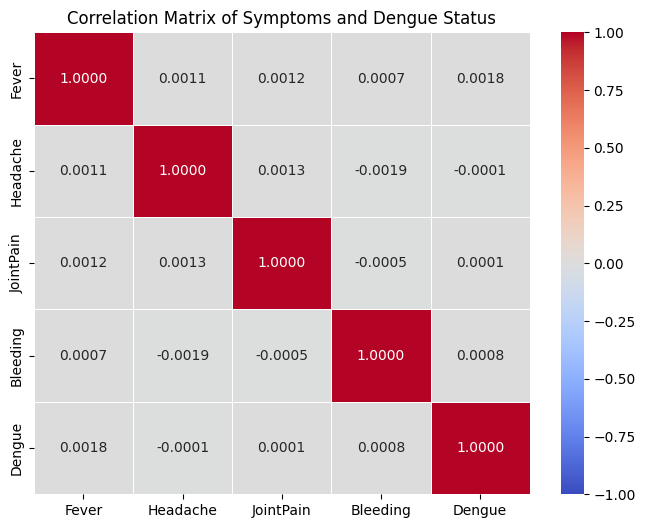

In [23]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.4f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Matrix of Symptoms and Dengue Status')
plt.show()

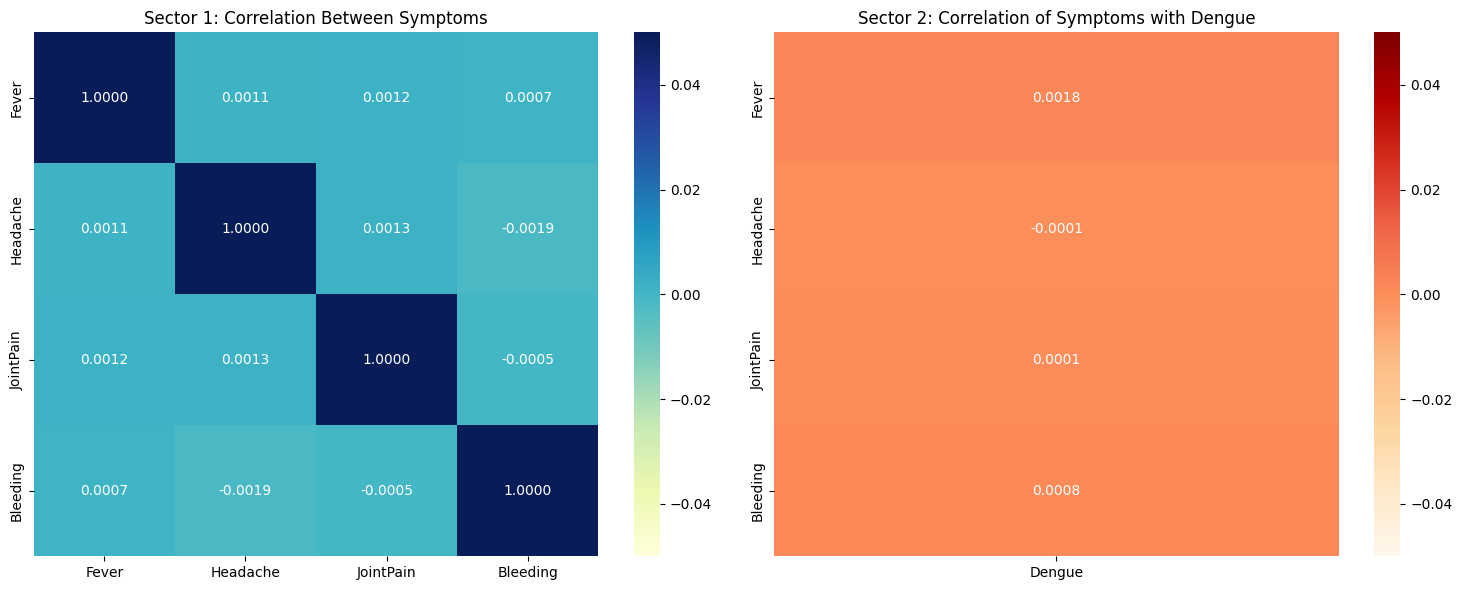

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

symptom_corr = correlation_matrix.loc[symptoms, symptoms]
sns.heatmap(symptom_corr, annot=True, cmap='YlGnBu', fmt='.4f', ax=axes[0], vmin=-0.05, vmax=0.05)
axes[0].set_title('Sector 1: Correlation Between Symptoms')

dengue_corr = correlation_matrix.loc[symptoms, ['Dengue']]
sns.heatmap(dengue_corr, annot=True, cmap='OrRd', fmt='.4f', ax=axes[1], vmin=-0.05, vmax=0.05)
axes[1].set_title('Sector 2: Correlation of Symptoms with Dengue')

plt.tight_layout()
plt.show()